# Chapitre 9 - Exercices 9.4 à 9.6 : backfitting dégénéré, degrés de liberté d'un arbre, données ozone

- **Exercice 9.4** : backfitting avec deux fois le même lisseur ; limite des résidus,
  monotonie de la somme des carrés.
- **Exercice 9.5** : degrés de liberté d'un arbre de régression, par simulation et par
  une matrice de lissage approchée.
- **Exercice 9.6** : modèle additif, arbre, MARS et PRIM sur les données ozone,
  comparés à l'affichage conditionnel de la figure 6.9.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch09_arbres import (SplineLisseur, MatriceLisseur, backfitting, ArbreCART,
                             cart_cv, MARS, GAM, prim, prim_peel, in_box, box_rules)

set_style()
rng = np.random.RandomState(0)

## Exercice 9.4 : Backfitting avec deux termes identiques

**Énoncé (reformulé).** On utilise le **même** lisseur $S$ pour estimer les deux termes
d'un modèle additif à deux termes (les deux variables sont identiques). On suppose $S$
symétrique, à valeurs propres dans $[0,1)$.

1. Montrer que le résidu du backfitting converge vers $(I+S)^{-1}(I-S)\mathbf y$ et que
   la somme des carrés résiduelle converge **en croissant**.
2. La somme des carrés résiduelle peut-elle croître dans des situations moins
   structurées ?
3. Comparer cet ajustement à celui d'un seul terme lissé par $S$. (Indication : utiliser
   la décomposition spectrale de $S$.)

### Rappel : décomposition spectrale

Une matrice réelle symétrique $S$ ($N\times N$) s'écrit $S = UDU^T$ avec $U$ orthogonale
($U^TU=I$, colonnes $u_1,\dots,u_N$ orthonormées) et $D=\mathrm{diag}(d_1,\dots,d_N)$
(théorème spectral). Écrivons $\mathbf y=\sum_k c_ku_k$ avec $c_k=u_k^T\mathbf y$. Toute
matrice de la forme $g(S)$ (polynôme ou fraction rationnelle en $S$) agit
**composante par composante** : $g(S)\mathbf y = \sum_k g(d_k)c_ku_k$. Ici
$d_k\in[0,1)$.

### 1. Limite du résidu

On part de $\mathbf f_1^{(0)}=\mathbf f_2^{(0)}=0$ (initialisation standard ; on omet
la constante en supposant $\mathbf y$ centrée). Le cycle $m\ge1$ est
$$\mathbf f_1^{(m)} = S(\mathbf y-\mathbf f_2^{(m-1)}),\qquad \mathbf f_2^{(m)} =
S(\mathbf y-\mathbf f_1^{(m)}).$$
Tous les itérés sont des fonctions de $S$ appliquées à $\mathbf y$ : on peut raisonner
sur **une composante** $k$. Notons $d=d_k$, $c=c_k$, et $a_m$, $b_m$ les composantes de
$\mathbf f_1^{(m)}$, $\mathbf f_2^{(m)}$ sur $u_k$ :
$$a_m = d(c-b_{m-1}),\qquad b_m = d(c-a_m),\qquad b_0=0 .$$

En substituant : $b_m = dc - d^2c + d^2b_{m-1}$. Le point fixe $b^*$ vérifie
$b^*(1-d^2) = dc(1-d)$, soit $b^* = \dfrac{dc}{1+d}$, et
$$b_m - b^* = d^2(b_{m-1}-b^*) \quad\Rightarrow\quad b_m = b^*\big(1-d^{2m}\big)
\xrightarrow[m\to\infty]{} b^* \quad (0\le d<1).$$
De même $a_m = dc - db_{m-1} \to dc-db^* = \dfrac{dc}{1+d} = b^*$. La composante du
résidu $\mathbf y-\mathbf f_1-\mathbf f_2$ tend donc vers
$$c - \frac{2dc}{1+d} = \frac{1-d}{1+d}\,c ,$$
ce qui, recomposé sur toutes les composantes, s'écrit
$$\mathbf r^{(m)}\longrightarrow (I+S)^{-1}(I-S)\,\mathbf y .\qquad\blacksquare$$

### La somme des carrés converge en croissant

Calculons exactement la composante du résidu après le cycle $m$. Avec $a_m = dc -
db_{m-1} = b^* + b^*d^{2m-1}$ (car $dc-db^* = b^*$ et $db^*d^{2m-2} = b^*d^{2m-1}$) et
$b_m = b^*-b^*d^{2m}$ :
$$\rho_m := c - a_m - b_m = (c-2b^*) - b^*d^{2m-1}(1-d) = \frac{1-d}{1+d}c -
\frac{dc}{1+d}\,d^{2m-1}(1-d) = \frac{(1-d)c}{1+d}\big(1-d^{2m}\big).$$
Ainsi $|\rho_m| = \frac{1-d}{1+d}|c|\,(1-d^{2m})$ est **croissante** en $m$ et tend vers
$\frac{1-d}{1+d}|c|$. Par l'orthonormalité de $U$, $\mathrm{RSS}_m = \|\mathbf
r^{(m)}\|^2 = \sum_k\rho_{m,k}^2$ est une somme de termes croissants : la somme des
carrés résiduelle **croît** vers sa limite $\|(I+S)^{-1}(I-S)\mathbf y\|^2$.

**Vérification numérique.** On prend pour $S$ une spline de lissage avec un petit terme
de ridge (valeurs propres dans $[0,1)$).

In [2]:
N = 60
x = np.sort(rng.uniform(0, 1, N))
y = np.sin(6 * x) + 0.4 * rng.randn(N)
y = y - y.mean()
S = SplineLisseur(x, df=6, ridge=0.02).matrix()
I = np.eye(N)
ev = np.linalg.eigvalsh(S)
print("valeurs propres de S dans [%.3f, %.3f]" % (ev.min(), ev.max()))
_, F, it, rss = backfitting(y, [MatriceLisseur(S), MatriceLisseur(S)], intercept=False,
                            tol=1e-13, max_iter=5000, history=True)
r_lim = np.linalg.solve(I + S, (I - S) @ y)
print("cycles : %d ; écart du résidu final à (I+S)^-1 (I-S) y : %.2e"
      % (it, np.abs(y - F.sum(1) - r_lim).max()))
print("RSS croissante à chaque cycle :", np.all(np.diff(rss) >= -1e-12))

valeurs propres de S dans [0.000, 0.980]
cycles : 613 ; écart du résidu final à (I+S)^-1 (I-S) y : 2.13e-14
RSS croissante à chaque cycle : True


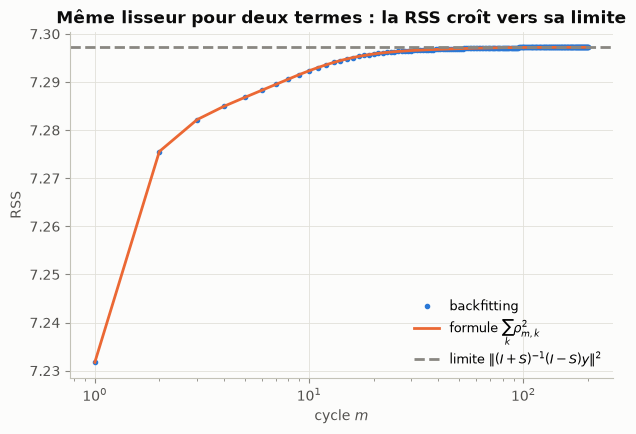

In [3]:
d, U = np.linalg.eigh(S)
c = U.T @ y
m = np.arange(1, len(rss) + 1)
rss_th = [np.sum(((1 - d) / (1 + d) * c * (1 - d ** (2 * k))) ** 2) for k in m]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(m[:200], rss[:200], "o", ms=3, color=BLUE, label="backfitting")
ax.plot(m[:200], rss_th[:200], color=ORANGE, label="formule $\\sum_k \\rho_{m,k}^2$")
ax.axhline(np.sum(r_lim ** 2), color=GRAY, ls="--", label="limite $\\|(I+S)^{-1}(I-S)y\\|^2$")
ax.set(title="Même lisseur pour deux termes : la RSS croît vers sa limite",
       xlabel="cycle $m$", ylabel="RSS", xscale="log")
ax.legend()
plt.show()

### 2. Et dans des situations moins structurées ?

**Ce que minimise le backfitting.** Pour un lisseur symétrique $S_j$ à valeurs propres
dans $(0,1]$, posons $K_j=S_j^{-1}-I$ (symétrique positive). Alors $S_j\mathbf r$ est le
minimiseur de $\|\mathbf r-\mathbf f\|^2 + \mathbf f^TK_j\mathbf f$ (le gradient
$-2(\mathbf r-\mathbf f)+2K_j\mathbf f$ s'annule en $S_j^{-1}\mathbf f=\mathbf r$). Le
backfitting est donc une descente par blocs sur le critère **pénalisé**
$$\mathrm{PRSS}(\mathbf f_1,\dots,\mathbf f_p) = \Big\|\mathbf y-\sum_j\mathbf
f_j\Big\|^2 + \sum_j\mathbf f_j^TK_j\mathbf f_j ,$$
qui décroît à chaque étape. Mais rien n'oblige la **RSS** seule à décroître : partant de
$\mathbf f=0$ (pénalité nulle), l'algorithme peut « échanger » de l'ajustement contre de
la pénalité.

Dans l'exemple précédent, PRSS décroît pendant que RSS croît. Voyons une situation moins
structurée : deux variables **différentes mais presque confondues**
($x_2 = x_1 + 0.01\,\varepsilon$) et deux splines de lissage **différentes** (4 et 8
degrés de liberté, petit ridge). On observe la RSS et le critère PRSS à chaque cycle.

In [4]:
def prss(y, F, mats):
    tot = np.sum((y - F.sum(1)) ** 2)
    for j, Sj in enumerate(mats):
        Kj = np.linalg.inv(Sj) - np.eye(len(y))
        tot += F[:, j] @ Kj @ F[:, j]
    return tot

N = 100
x1 = rng.uniform(0, 1, N)
x2 = x1 + 0.01 * rng.randn(N)
y2 = np.sin(4 * x1) + 0.5 * rng.randn(N)
y2 = y2 - y2.mean()
mats = [SplineLisseur(x1, df=4, ridge=1e-3).matrix(), SplineLisseur(x2, df=8, ridge=1e-3).matrix()]
mats = [0.5 * (M + M.T) for M in mats]
R, Pn = [], []
for n_c in range(1, 41):
    _, F2, _ = backfitting(y2, [MatriceLisseur(M) for M in mats], intercept=False, tol=0,
                           max_iter=n_c)
    R.append(np.sum((y2 - F2.sum(1)) ** 2))
    Pn.append(prss(y2, F2, mats))
print("RSS : premier cycle %.4f, dernier cycle %.4f" % (R[0], R[-1]))
print("PRSS décroissante :", np.all(np.diff(Pn) <= 1e-8))

RSS : premier cycle 19.8110, dernier cycle 20.0793
PRSS décroissante : True


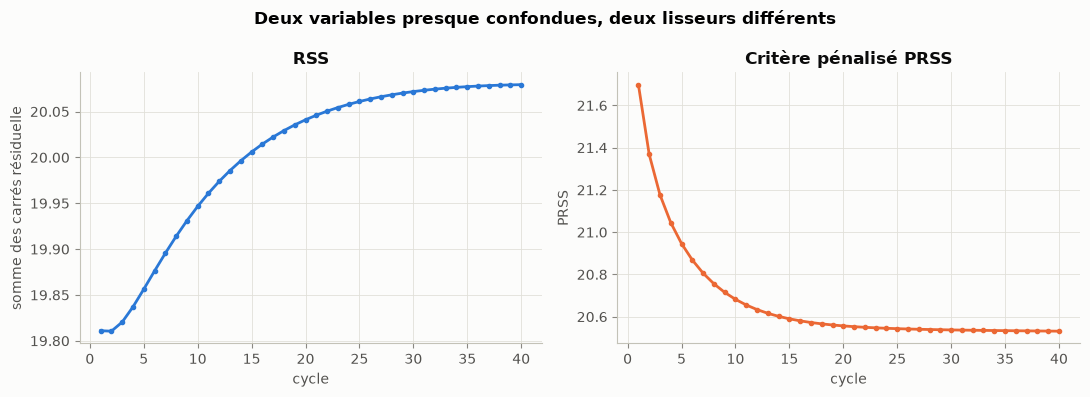

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, 41), R, "o-", ms=3, color=BLUE)
axes[0].set(title="RSS", xlabel="cycle", ylabel="somme des carrés résiduelle")
axes[1].plot(range(1, 41), Pn, "o-", ms=3, color=ORANGE)
axes[1].set(title="Critère pénalisé PRSS", xlabel="cycle", ylabel="PRSS")
fig.suptitle("Deux variables presque confondues, deux lisseurs différents", fontweight="bold")
fig.tight_layout()
plt.show()

Le critère pénalisé décroît à chaque cycle, comme prévu, tandis que la RSS **augmente**
vers sa limite (à un minuscule palier près au début). **Réponse : oui**, la RSS peut
converger en croissant dans des situations moins structurées que celle de l'énoncé :
ici, deux lisseurs différents sur deux variables seulement *presque* identiques. Dès que
les lisseurs ne sont pas des projections, rien n'impose à la RSS d'être monotone ; avec
des projections (exercice 9.3), en revanche, chaque étape minimise exactement la RSS par
rapport à un bloc, qui ne peut alors que décroître.

### 3. Comparaison avec un seul terme lissé par $S$

Composante par composante (valeur propre $d$) :

| | un terme : $S\mathbf y$ | deux termes (limite) : $2S(I+S)^{-1}\mathbf y$ |
|---|---|---|
| facteur d'ajustement | $d$ | $\dfrac{2d}{1+d}$ |
| facteur de résidu | $1-d$ | $\dfrac{1-d}{1+d}$ |

Comme $\frac{2d}{1+d}-d = \frac{d(1-d)}{1+d}\ge0$, le modèle à deux termes identiques
**lisse moins** : il équivaut à un seul lisseur $S' = 2S(I+S)^{-1}$, de valeurs propres
$2d/(1+d)\in[d,1)$. Les composantes très lissées ($d\approx1$) et très atténuées
($d\approx0$) sont peu changées ; les composantes intermédiaires sont nettement moins
atténuées. Les degrés de liberté passent de $\mathrm{tr}(S)=\sum d_k$ à
$\sum 2d_k/(1+d_k)$, mais sans doubler.

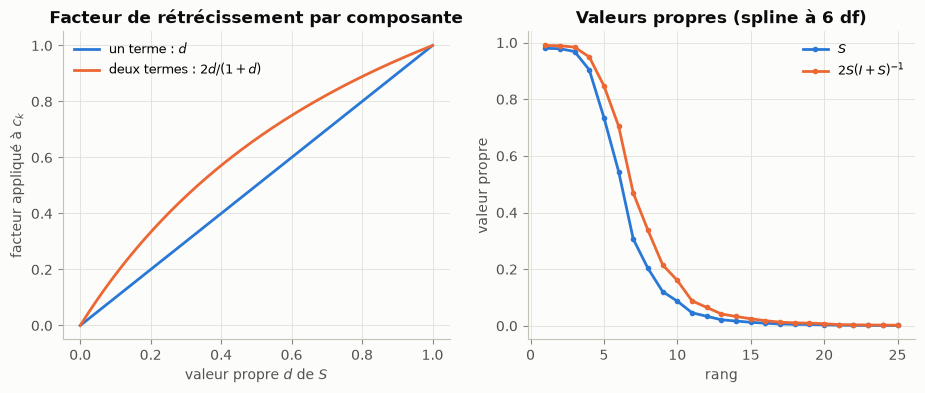

df : un terme 6.00, deux termes identiques 6.98


In [6]:
dd = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(dd, dd, color=BLUE, label="un terme : $d$")
axes[0].plot(dd, 2 * dd / (1 + dd), color=ORANGE, label="deux termes : $2d/(1+d)$")
axes[0].set(title="Facteur de rétrécissement par composante", xlabel="valeur propre $d$ de $S$",
            ylabel="facteur appliqué à $c_k$")
axes[0].legend()
k_ = np.arange(1, N + 1)
dS = np.sort(np.linalg.eigvalsh(SplineLisseur(x, df=6, ridge=0.02).matrix()))[::-1]
axes[1].plot(np.arange(1, len(dS) + 1)[:25], dS[:25], "o-", ms=3, color=BLUE, label="$S$")
axes[1].plot(np.arange(1, len(dS) + 1)[:25], (2 * dS / (1 + dS))[:25], "o-", ms=3,
             color=ORANGE, label="$2S(I+S)^{-1}$")
axes[1].set(title="Valeurs propres (spline à 6 df)", xlabel="rang", ylabel="valeur propre")
axes[1].legend()
plt.show()
print("df : un terme %.2f, deux termes identiques %.2f" % (dS.sum(), np.sum(2 * dS / (1 + dS))))

> **À retenir.** Avec deux fois le même lisseur, le backfitting converge vers un
> ajustement $2S(I+S)^{-1}\mathbf y$, moins lissé qu'un seul passage de $S$ ; la RSS y
> converge en croissant. Le backfitting minimise un critère pénalisé, pas la RSS : celle-ci
> peut augmenter en cours d'itération dès que les lisseurs ne sont pas des projections.

## Exercice 9.5 : Degrés de liberté d'un arbre de régression

**Énoncé (reformulé).** Pour des données $y_i$ de moyenne $f(x_i)$ et de variance
$\sigma^2$, et une procédure d'ajustement $\mathbf y\mapsto\hat{\mathbf y}$, on définit
les degrés de liberté par $\mathrm{df}=\sum_i\mathrm{cov}(y_i,\hat y_i)/\sigma^2$
(cf. éq. (7.6) du livre). On ajuste un arbre de régression sur $X_1,\dots,X_p$.

(a) Donner une formule approximative des degrés de liberté en fonction du nombre $m$ de
feuilles.
(b) Tirer 100 observations de $X_1,\dots,X_{10}$ gaussiennes standard indépendantes, et
les fixer.
(c) Tirer les réponses, aussi gaussiennes standard ($\sigma^2=1$) et indépendantes des
prédicteurs. Ajuster des arbres de taille fixée 1, 5 et 10 feuilles et estimer leurs
degrés de liberté (moyenner sur dix simulations de la réponse).
(d) Comparer (a) et (c) et commenter.
(e) Si l'arbre était une opération linéaire $\hat{\mathbf y}=S\mathbf y$, on aurait
$\mathrm{df}=\mathrm{tr}(S)$. Proposer une façon de calculer une matrice $S$ approchée
pour un arbre, la calculer et comparer les degrés de liberté obtenus à (a) et (c).

### (a) Une formule naïve

Si la partition en $m$ feuilles était **fixée à l'avance** (indépendante de $\mathbf y$),
l'arbre serait la projection orthogonale $P$ sur l'espace engendré par les $m$
indicatrices de feuilles : $\hat{\mathbf y}=P\mathbf y$, et
$$\sum_i\mathrm{cov}(y_i,\hat y_i) = \sum_i\sum_k P_{ik}\,\mathrm{cov}(y_i,y_k) =
\sigma^2\,\mathrm{tr}(P) = \sigma^2 m,$$
car les $y_i$ sont indépendants et la trace d'une projection est la dimension de son
image. Formule approximative : $\mathrm{df}\approx m$.

Mais la partition est **choisie** à l'aide de $\mathbf y$ (variable et seuil de chaque
coupure, parmi environ $p(N-1)$ candidats) : chaque coupure « consomme » plus qu'un
paramètre, et l'on s'attend à $\mathrm{df}>m$, à la manière des 3 paramètres par nœud de
MARS (section 9.4).

### (b)-(c) Simulation

Les arbres de taille fixée sont obtenus par croissance « meilleur d'abord » (on découpe
toujours la feuille dont la coupure réduit le plus la somme des carrés) jusqu'à $m$
feuilles ; on impose au moins 5 observations par feuille. Comme $\mathbb E(y_i)=0$,
$\mathrm{cov}(y_i,\hat y_i)=\mathbb E(y_i\hat y_i)$, que l'on estime par la moyenne sur
les simulations de $\sum_iy_i\hat y_i$.

In [7]:
Xd = rng.randn(100, 10)  # (b) prédicteurs fixés
tailles = [1, 5, 10]

def ajuste(yv, m):
    return ArbreCART(task="regression", max_leaves=m, min_samples_split=2,
                     min_samples_leaf=5).fit(Xd, yv).predict(Xd)

def df_simulation(n_sim, rs):
    out = {m: [] for m in tailles}
    for _ in range(n_sim):
        yv = rs.randn(100)
        for m in tailles:
            out[m].append(yv @ ajuste(yv, m))
    return {m: (np.mean(v), np.std(v, ddof=1) / np.sqrt(n_sim)) for m, v in out.items()}

df10 = df_simulation(10, np.random.RandomState(1))
df500 = df_simulation(500, np.random.RandomState(2))
pd.DataFrame({"m (feuilles)": tailles,
              "df, 10 simulations": [df10[m][0] for m in tailles],
              "erreur-type (10)": [df10[m][1] for m in tailles],
              "df, 500 simulations": [df500[m][0] for m in tailles],
              "erreur-type (500)": [df500[m][1] for m in tailles]}).round(2)

,m (feuilles),"df, 10 simulations",erreur-type (10),"df, 500 simulations",erreur-type (500)
0,1,0.74,0.24,1.05,0.06
1,5,27.80,1.77,28.80,0.26
2,10,47.99,2.55,49.39,0.37


Dix simulations (comme le suggère l'énoncé) donnent déjà l'ordre de grandeur, mais avec
une erreur-type de plusieurs unités ; 500 simulations stabilisent l'estimation.
Traçons les degrés de liberté pour toutes les tailles de 1 à 12 feuilles.

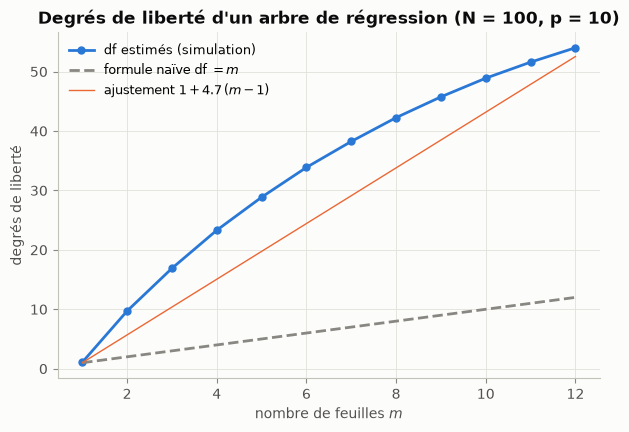

In [8]:
rs = np.random.RandomState(3)
toutes = np.arange(1, 13)
acc = np.zeros(len(toutes))
n_sim = 200
for _ in range(n_sim):
    yv = rs.randn(100)
    acc += [yv @ ajuste(yv, m) for m in toutes]
df_m = acc / n_sim
pente = np.polyfit(toutes - 1, df_m - 1, 1)[0]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(toutes, df_m, "o-", color=BLUE, label="df estimés (simulation)")
ax.plot(toutes, toutes, color=GRAY, ls="--", label="formule naïve df $= m$")
ax.plot(toutes, 1 + pente * (toutes - 1), color=ORANGE, lw=1,
        label="ajustement $1 + %.1f\\,(m-1)$" % pente)
ax.set(title="Degrés de liberté d'un arbre de régression (N = 100, p = 10)",
       xlabel="nombre de feuilles $m$", ylabel="degrés de liberté")
ax.legend()
plt.show()

### (d) Comparaison et discussion

- Pour $m=1$ (pas de coupure), l'arbre prédit la moyenne $\bar y$ : $\mathrm{df}=1$,
  formule naïve exacte.
- Pour $m=5$ et $m=10$, les degrés de liberté effectifs sont **plusieurs fois
  supérieurs** à $m$ : chaque coupure supplémentaire coûte environ cinq paramètres
  (pente ci-dessus) au lieu d'un. La recherche du meilleur couple (variable, seuil)
  parmi $10\times 99$ candidats « adapte » l'arbre au bruit : les moyennes des feuilles
  sont systématiquement plus éloignées de 0 que si la partition était fixée.
- Conséquence pratique : un critère comme $C_p$ ou AIC calculé avec $d=m$ paramètres
  sous-estimerait gravement l'optimisme de l'erreur d'apprentissage d'un arbre ; c'est
  une raison de choisir la taille par **validation croisée**.

### (e) Une matrice de lissage approchée

L'arbre n'est pas linéaire en $\mathbf y$ (la partition dépend de $\mathbf y$). Trois
approximations naturelles :

1. **Partition gelée** : on fixe la partition obtenue sur $\mathbf y$ et l'on prend
   $S=P$, la projection sur les indicatrices des feuilles ($P_{ik}=1/N_m$ si $i$ et $k$
   sont dans la même feuille $m$). Alors $\mathrm{tr}(S)=m$ : on retrouve (a).
2. **Différences finies** : la $j$-ième colonne de $S$ est approchée par
   $S_{\cdot j}\approx[\hat{\mathbf y}(\mathbf y+\delta e_j)-\hat{\mathbf
   y}(\mathbf y)]/\delta$, en **refaisant pousser l'arbre** sur la réponse perturbée.
   Pour $\delta$ petit, la partition ne bouge pas et l'on retombe sur $P$ ; pour $\delta$
   de l'ordre de $\sigma$, les changements de partition sont pris en compte.
3. **Perturbations aléatoires** (degrés de liberté généralisés de Ye, 1998) : on tire
   $\boldsymbol\delta\sim\mathcal N(0,\tau^2I)$, on réajuste, et l'on estime
   $S_{ii}\approx\partial\hat y_i/\partial y_i$ par la pente de la régression de
   $\hat y_i(\mathbf y+\boldsymbol\delta)$ sur $\delta_i$ ; $\mathrm{df}\approx\sum_i
   S_{ii}$.

In [9]:
rs = np.random.RandomState(4)
y0 = rs.randn(100)
lignes = []
for m in [5, 10]:
    base = ajuste(y0, m)
    t = ArbreCART(task="regression", max_leaves=m, min_samples_split=2,
                  min_samples_leaf=5).fit(Xd, y0)
    feuilles = t.apply(Xd)
    P = (feuilles[:, None] == feuilles[None, :]) / np.bincount(feuilles)[feuilles][:, None]
    ligne = {"m": m, "partition gelée tr(P)": np.trace(P)}
    for delta in [0.01, 0.5, 1.0]:
        diag = [(ajuste(y0 + delta * np.eye(100)[j], m)[j] - base[j]) / delta for j in range(100)]
        ligne["diff. finies, delta=%.2g" % delta] = np.sum(diag)
    tau, B = 1.0, 100
    D_ = rs.randn(B, 100) * tau
    Yh = np.array([ajuste(y0 + D_[b], m) for b in range(B)])
    pentes = [np.polyfit(D_[:, i], Yh[:, i], 1)[0] for i in range(100)]
    ligne["Ye (tau=1)"] = np.sum(pentes)
    ligne["simulation (c)"] = df500[m][0]
    lignes.append(ligne)
pd.DataFrame(lignes).round(1)

,m,partition gelée tr(P),"diff. finies, delta=0.01","diff. finies, delta=0.5","diff. finies, delta=1",Ye (tau=1),simulation (c)
0,5,5.0,5.0,37.9,31.9,28.9,28.8
1,10,10.0,10.0,30.7,41.9,49.1,49.4


- La **partition gelée** donne exactement $m$ : elle ignore la sélection des coupures.
- Les **différences finies** avec $\delta$ petit donnent aussi $m$ (la partition ne
  change pas, la dérivée vaut $1/N_m$ pour chaque observation de la feuille). Avec
  $\delta$ de l'ordre de $\sigma$, une perturbation d'une seule observation peut
  modifier une coupure, et la trace augmente.
- La méthode de **Ye** (perturbations de toutes les réponses à la fois, $\tau=\sigma$)
  capte l'essentiel de l'effet de sélection et se rapproche des degrés de liberté
  obtenus par simulation en (c). C'est une manière générale d'attribuer des degrés de
  liberté à une procédure non linéaire.

> **À retenir.** La formule naïve $\mathrm{df}=m$ n'est valable que si la partition est
> fixée d'avance. La sélection gloutonne des coupures fait d'un arbre à $m$ feuilles une
> procédure de complexité bien supérieure (ici environ $1+5(m-1)$ degrés de liberté pour
> $N=100$, $p=10$). Une matrice de lissage « linéarisée » doit tenir compte des
> changements de partition (perturbations finies) pour refléter cette complexité.

## Exercice 9.6 : Les données ozone

**Énoncé (reformulé).** On reprend les données ozone de la figure 6.9 (111 jours :
concentration d'ozone, température, vitesse du vent, rayonnement solaire).

(a) Ajuster un modèle additif à la racine cubique de la concentration d'ozone, en
fonction de la température, du vent et du rayonnement. Comparer à l'affichage en treillis
de la figure 6.9.
(b) Ajuster des arbres, MARS et PRIM aux mêmes données et comparer aux résultats de (a)
et de la figure 6.9.

In [10]:
oz = datasets.load_ozone()
noms = ["temperature", "wind", "radiation"]
Xo = oz[noms].to_numpy(float)
yo = np.cbrt(oz["ozone"].to_numpy(float))
print(oz.describe().round(1))

       ozone  radiation  temperature   wind
count  111.0      111.0        111.0  111.0
mean    42.1      184.8         77.8    9.9
std     33.3       91.2          9.5    3.6
min      1.0        7.0         57.0    2.3
25%     18.0      113.5         71.0    7.4
50%     31.0      207.0         79.0    9.7
75%     62.0      255.5         84.5   11.5
max    168.0      334.0         97.0   20.7


### (a) Modèle additif

On ajuste $\sqrt[3]{\text{ozone}} = \alpha + f_1(\text{température}) + f_2(\text{vent}) +
f_3(\text{rayonnement}) + \varepsilon$ par backfitting, avec des splines de lissage
exactes (nœuds en toutes les valeurs) à 4 degrés de liberté nominaux
($\mathrm{tr}(S_j)-1=4$).

In [11]:
gam_oz = GAM(df=4, n_knots=None).fit(Xo, yo)
res = yo - gam_oz.decision_function(Xo)
print("alpha = %.3f, cycles de backfitting = %d" % (gam_oz.alpha_, gam_oz.n_iter_))
print("R2 d'apprentissage = %.3f" % (1 - np.sum(res ** 2) / np.sum((yo - yo.mean()) ** 2)))

alpha = 3.248, cycles de backfitting = 9
R2 d'apprentissage = 0.771


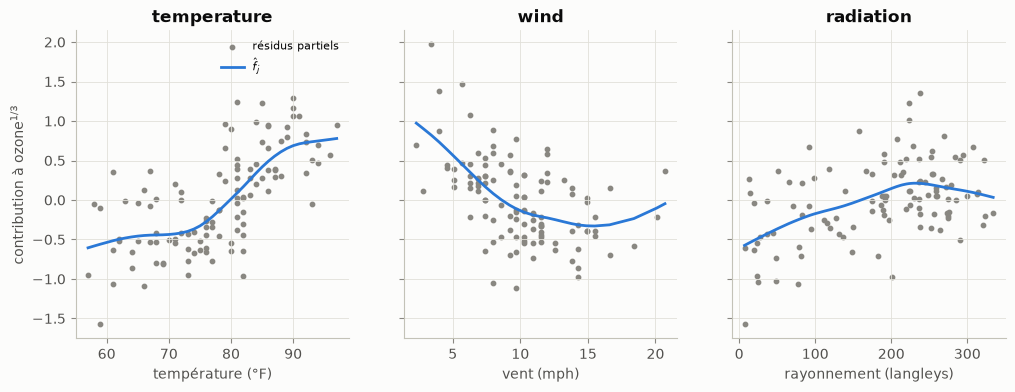

In [12]:
etiquettes = ["température (°F)", "vent (mph)", "rayonnement (langleys)"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for j, ax in enumerate(axes):
    o = np.argsort(Xo[:, j])
    ax.scatter(Xo[:, j], gam_oz.F_[:, j] + res, s=10, color=GRAY, label="résidus partiels")
    ax.plot(Xo[o, j], gam_oz.F_[o, j], color=BLUE, label=r"$\hat f_j$")
    ax.set(xlabel=etiquettes[j], title=noms[j])
axes[0].set_ylabel("contribution à ozone$^{1/3}$")
axes[0].legend(fontsize=8)
plt.show()

Lecture : l'ozone augmente avec la **température** (fortement au-delà de 75 °F),
diminue avec le **vent** (dispersion des polluants), et augmente avec le **rayonnement**
jusqu'à environ 250 langleys avant de plafonner (voire de décroître).

**Comparaison avec la figure 6.9.** La figure 6.9 est un affichage **conditionnel** :
chaque panneau sélectionne les jours dont la température et le vent sont dans un
intervalle donné (environ 40 % de l'étendue de chaque variable) et trace l'ozone contre le
rayonnement avec une régression linéaire locale univariée. Reproduisons-le (3 × 3
panneaux) et superposons la prédiction du modèle additif au centre de chaque panneau.

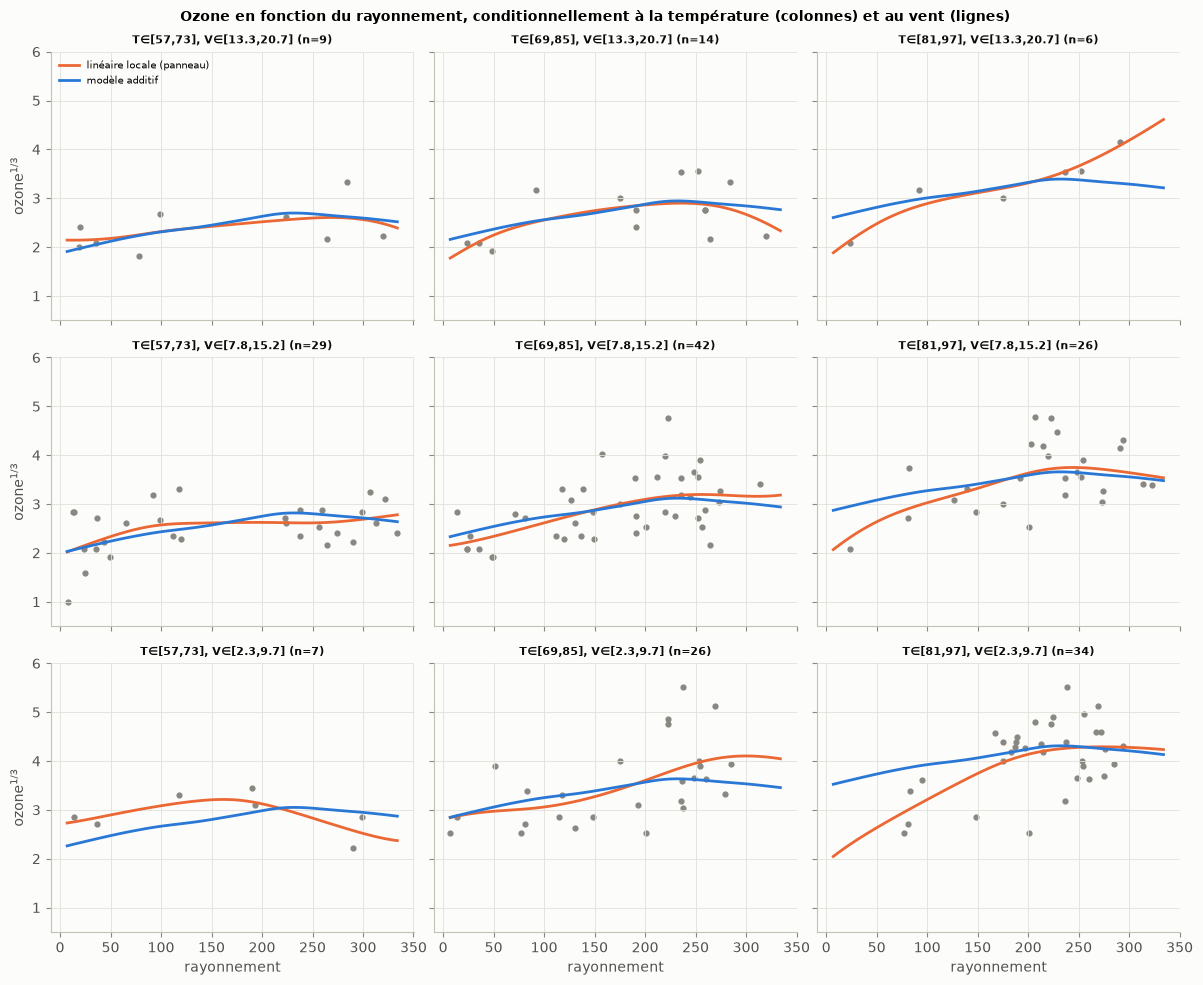

In [13]:
def lin_local_1d(x, y, grille, h):
    """Régression linéaire locale (noyau gaussien de largeur h) évaluée sur une grille."""
    out = []
    B = np.column_stack([np.ones(len(x)), x])
    for g in grille:
        w = np.exp(-0.5 * ((x - g) / h) ** 2)
        coef = np.linalg.lstsq(B * np.sqrt(w)[:, None], y * np.sqrt(w), rcond=None)[0]
        out.append(coef[0] + coef[1] * g)
    return np.array(out)

def intervalles(v, n=3, largeur=0.4):
    lo, hi = v.min(), v.max()
    centres = np.linspace(lo + largeur / 2 * (hi - lo), hi - largeur / 2 * (hi - lo), n)
    return [(c - largeur / 2 * (hi - lo), c + largeur / 2 * (hi - lo)) for c in centres]

grille_r = np.linspace(Xo[:, 2].min(), Xo[:, 2].max(), 100)
fig, axes = plt.subplots(3, 3, figsize=(12, 10), sharex=True, sharey=True)
for a, (wlo, whi) in enumerate(intervalles(Xo[:, 1])[::-1]):
    for b, (tlo, thi) in enumerate(intervalles(Xo[:, 0])):
        ax = axes[a, b]
        sel = (Xo[:, 0] >= tlo) & (Xo[:, 0] <= thi) & (Xo[:, 1] >= wlo) & (Xo[:, 1] <= whi)
        ax.scatter(Xo[sel, 2], yo[sel], s=12, color=GRAY)
        if sel.sum() >= 5:
            ax.plot(grille_r, lin_local_1d(Xo[sel, 2], yo[sel], grille_r, 60), color=ORANGE,
                    label="linéaire locale (panneau)")
            Xg = np.column_stack([np.full(100, Xo[sel, 0].mean()), np.full(100, Xo[sel, 1].mean()),
                                  grille_r])
            ax.plot(grille_r, gam_oz.decision_function(Xg), color=BLUE,
                    label="modèle additif")
        ax.set_title("T∈[%.0f,%.0f], V∈[%.1f,%.1f] (n=%d)" % (tlo, thi, wlo, whi, sel.sum()),
                     fontsize=8)
        ax.set_ylim(0.5, 6)
for ax in axes[-1]:
    ax.set_xlabel("rayonnement")
for ax in axes[:, 0]:
    ax.set_ylabel("ozone$^{1/3}$")
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle("Ozone en fonction du rayonnement, conditionnellement à la température (colonnes) "
             "et au vent (lignes)", fontweight="bold", fontsize=10)
fig.tight_layout()
plt.show()

Dans le modèle additif, les courbes d'un panneau à l'autre sont **translatées
verticalement** (même forme en rayonnement, niveau fixé par la température et le vent).
L'affichage conditionnel suggère une **interaction** : l'effet du rayonnement semble plus
marqué par temps chaud et peu venté, et plus plat quand il fait frais et venteux. Avec
111 observations réparties sur 9 panneaux, ces différences restent cependant fragiles ;
le modèle additif en donne un bon résumé global, que l'on peut tester contre des
modèles avec interactions (MARS ci-dessous).

### (b) Arbre, MARS et PRIM

Pour comparer honnêtement les méthodes, on estime leur erreur de prédiction par
**validation croisée à 10 plis** (erreur quadratique moyenne sur $\sqrt[3]{\text{ozone}}$),
en incluant le modèle linéaire comme référence.

In [14]:
def vc(ajusteur, n_folds=10, seed=0):
    plis = np.random.RandomState(seed).permutation(len(yo)) % n_folds
    err = np.zeros(len(yo))
    for f in range(n_folds):
        tr, te = plis != f, plis == f
        err[te] = (yo[te] - ajusteur(Xo[tr], yo[tr], Xo[te])) ** 2
    return err.mean()

def lineaire(Xa, ya, Xb):
    A = np.column_stack([np.ones(len(ya)), Xa])
    return np.column_stack([np.ones(len(Xb)), Xb]) @ np.linalg.lstsq(A, ya, rcond=None)[0]

def additif(Xa, ya, Xb):
    return GAM(df=4, n_knots=None).fit(Xa, ya).decision_function(Xb)

def arbre_cv(Xa, ya, Xb):
    t = ArbreCART(task="regression", min_samples_split=10, min_samples_leaf=5).fit(Xa, ya)
    al, sub = t.pruning_path()
    beta = np.r_[np.sqrt(al[:-1] * al[1:]), al[-1] * 1.5]
    E = cart_cv(Xa, ya, beta, n_folds=5, rng=np.random.RandomState(1), task="regression",
                min_samples_split=10, min_samples_leaf=5)
    return t.predict(Xb, sub[int(np.argmin(E.mean(0)))])

def mars1(Xa, ya, Xb):
    return MARS(max_terms=15, max_degree=1, n_knots=15).fit(Xa, ya).predict(Xb)

def mars2(Xa, ya, Xb):
    return MARS(max_terms=15, max_degree=2, n_knots=15).fit(Xa, ya).predict(Xb)

scores = {"linéaire": vc(lineaire), "additif (GAM)": vc(additif), "arbre élagué (VC)": vc(arbre_cv),
          "MARS additif": vc(mars1), "MARS degré 2": vc(mars2)}
pd.Series(scores, name="erreur quadratique de VC").round(3).to_frame()

,erreur quadratique de VC
linéaire,0.266
additif (GAM),0.236
arbre élagué (VC),0.350
MARS additif,0.222
MARS degré 2,0.225


**L'arbre** sur l'ensemble des données, élagué par validation croisée :

In [ ]:
t_oz = ArbreCART(task="regression", min_samples_split=10, min_samples_leaf=5).fit(Xo, yo)
al, sub = t_oz.pruning_path()
beta = np.r_[np.sqrt(al[:-1] * al[1:]), al[-1] * 1.5]
E = cart_cv(Xo, yo, beta, n_folds=10, rng=np.random.RandomState(1), task="regression",
            min_samples_split=10, min_samples_leaf=5)
k_best = int(np.argmin(E.mean(0)))
print(t_oz.describe(names=noms, is_leaf=sub[k_best], digits=2))

L'arbre coupe d'abord sur la **température**, puis sur le **vent** et le **rayonnement** :
les mêmes variables et les mêmes sens d'effet que le modèle additif, mais sous forme de
marches. Sa surface constante par morceaux est moins précise (erreur de VC plus grande) :
c'est le défaut de régularité des arbres en régression.

**MARS** avec interactions d'ordre 2 sur l'ensemble des données :

In [ ]:
mars_oz = MARS(max_terms=15, max_degree=2, n_knots=15).fit(Xo, yo)
for t in mars_oz.describe(noms):
    print(t)

MARS retrouve des effets en charnière cohérents avec les courbes du modèle additif
(croissance avec la température, décroissance avec le vent, montée puis plateau du
rayonnement). S'il retient des produits de charnières, ce sont des **interactions**
localisées, du type de celles que suggère la figure 6.9 ; leur apport en validation
croisée par rapport à la version additive indique si elles sont réelles ou
opportunistes.